# Experiment 10: Bagging and Boosting Ensembles on the Titanic Dataset
## Aim
Implement bagging and boosting ensemble methods on the Titanic dataset, compare their performance in terms of accuracy, precision, recall and F1-score, and discuss how each method improves performance along with its strengths and weaknesses.

## Theory
An **ensemble** combines many models to get better predictions than any single model. The two classic strategies attack different problems:

**Bagging (Bootstrap Aggregating)** reduces **variance**. Many copies of a high-variance base model (typically a fully grown decision tree) are trained **independently and in parallel**, each on a different bootstrap sample (random sample with replacement) of the training set. Predictions are combined by **majority vote**. Because each tree overfits in a different way, averaging their votes cancels out much of the noise.

**Boosting (AdaBoost)** reduces **bias**. Weak learners (typically shallow trees, often just one-split *stumps*) are trained **sequentially**. After each round, the samples that were misclassified get a **higher weight**, so the next learner focuses on the hard cases. Each learner also gets a vote weight based on its accuracy, and the final prediction is a **weighted vote**.

| | Bagging | Boosting (AdaBoost) |
|---|---|---|
| Training | Parallel, independent | Sequential, each depends on the previous |
| Base learner | Strong, high variance (deep trees) | Weak, high bias (stumps/shallow trees) |
| Sample handling | Random bootstrap samples | Re-weights misclassified samples |
| Combination | Equal-weight majority vote | Weighted vote |
| Mainly reduces | Variance (overfitting) | Bias (underfitting) |

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## Load the Titanic Dataset

In [2]:
df=sns.load_dataset('titanic')
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()
print()
print(df.isnull().sum())
print()
print(df['survived'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB

survived         0
pclass           0
sex              0
age            177
sibsp            

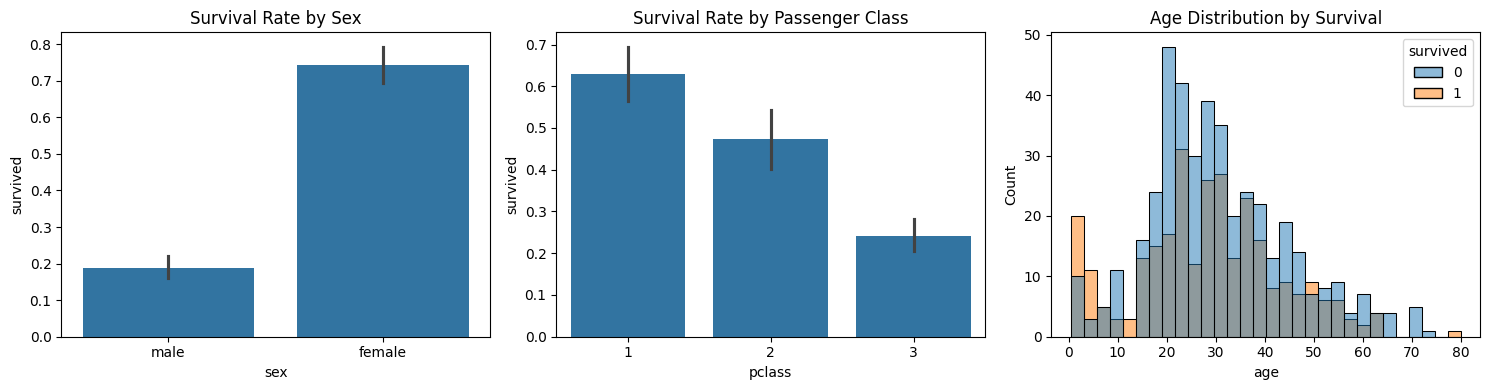

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.barplot(data=df,x='sex',y='survived',ax=axes[0])
axes[0].set_title('Survival Rate by Sex')
sns.barplot(data=df,x='pclass',y='survived',ax=axes[1])
axes[1].set_title('Survival Rate by Passenger Class')
sns.histplot(data=df,x='age',hue='survived',bins=30,ax=axes[2])
axes[2].set_title('Age Distribution by Survival')
plt.tight_layout()
plt.show()

## Preprocess the Dataset
- Columns used: `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`. Redundant columns (`class`, `who`, `adult_male`, `alive`, `embark_town`, `alone`) duplicate these, and `alive` would leak the target.
- `deck` is dropped because ~77% of its values are missing.
- Missing `age` (177 rows) is filled with the median; missing `embarked` (2 rows) with the mode.
- Categorical `sex` and `embarked` are one-hot encoded.

Tree-based models are insensitive to feature scaling, so no scaling is needed here.

In [5]:
data=df[['survived','pclass','sex','age','sibsp','parch','fare','embarked']].copy()
data['age']=data['age'].fillna(data['age'].median())
data['embarked']=data['embarked'].fillna(data['embarked'].mode()[0])
data=pd.get_dummies(data,columns=['sex','embarked'],drop_first=True)

print(data.isnull().sum().sum(),'missing values left')

X=data.drop(columns='survived')
y=data['survived']
print(X.columns.tolist())

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape,X_test.shape)

0 missing values left
['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']
(712, 8) (179, 8)


In [6]:
def evaluate(model,name):
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    return {'Model':name,
            'Accuracy':accuracy_score(y_test,pred),
            'Precision':precision_score(y_test,pred),
            'Recall':recall_score(y_test,pred),
            'F1-score':f1_score(y_test,pred)},pred

## Baselines: Single Decision Trees
A fully grown tree (low bias, high variance) is the natural base learner for bagging; a one-split stump (high bias, low variance) is the natural weak learner for boosting. Both are evaluated on their own first.

In [7]:
results=[];preds={}
for name,m in [('Single Tree (full depth)',DecisionTreeClassifier(random_state=42)),
               ('Single Stump (depth 1)',DecisionTreeClassifier(max_depth=1,random_state=42))]:
    r,p=evaluate(m,name)
    results.append(r);preds[name]=p
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1-score
0,Single Tree (full depth),0.821229,0.793651,0.724638,0.757576
1,Single Stump (depth 1),0.776536,0.737705,0.652174,0.692308


## Bagging
`BaggingClassifier` with 100 fully grown decision trees, each trained on a bootstrap sample. `oob_score=True` also gives a free out-of-bag accuracy estimate using the rows each tree did not see.

In [8]:
bag=BaggingClassifier(estimator=DecisionTreeClassifier(),n_estimators=100,oob_score=True,random_state=42)
r,p=evaluate(bag,'Bagging (100 trees)')
results.append(r);preds['Bagging (100 trees)']=p

print('Accuracy :',r['Accuracy'])
print('Precision:',r['Precision'])
print('Recall   :',r['Recall'])
print('F1-score :',r['F1-score'])
print('Out-of-bag accuracy estimate:',bag.oob_score_)

Accuracy : 0.8268156424581006
Precision: 0.796875
Recall   : 0.7391304347826086
F1-score : 0.7669172932330827
Out-of-bag accuracy estimate: 0.8103932584269663


## Boosting (AdaBoost)
`AdaBoostClassifier` with 100 decision stumps trained sequentially, with sample re-weighting after each round.

In [9]:
ada=AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),n_estimators=100,learning_rate=1.0,random_state=42)
r,p=evaluate(ada,'AdaBoost (100 stumps)')
results.append(r);preds['AdaBoost (100 stumps)']=p

print('Accuracy :',r['Accuracy'])
print('Precision:',r['Precision'])
print('Recall   :',r['Recall'])
print('F1-score :',r['F1-score'])

Accuracy : 0.7821229050279329
Precision: 0.75
Recall   : 0.6521739130434783
F1-score : 0.6976744186046512


## Comparison of Performance Metrics

In [10]:
results_df=pd.DataFrame(results).set_index('Model')
results_df

,Accuracy,Precision,Recall,F1-score
Model,,,,
Single Tree (full depth),0.821229,0.793651,0.724638,0.757576
Single Stump (depth 1),0.776536,0.737705,0.652174,0.692308
Bagging (100 trees),0.826816,0.796875,0.739130,0.766917
AdaBoost (100 stumps),0.782123,0.750000,0.652174,0.697674


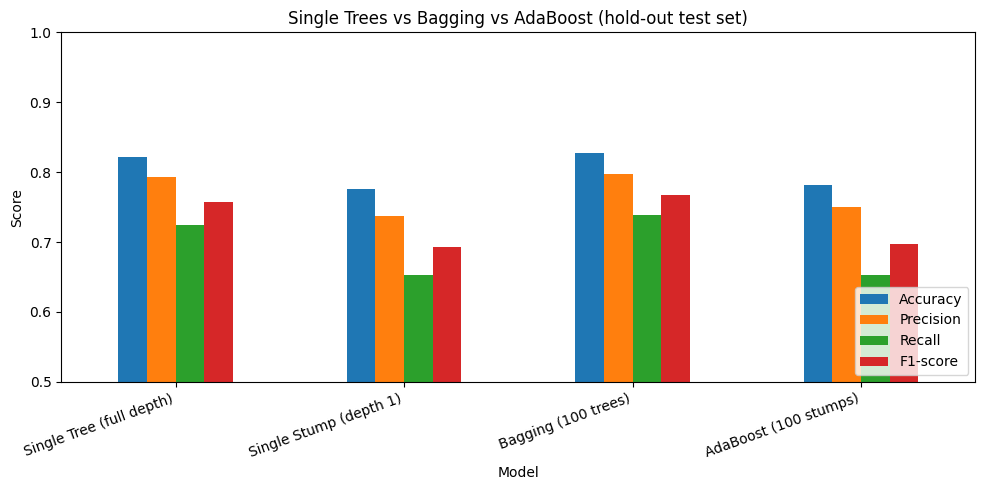

In [11]:
results_df.plot(kind='bar',figsize=(10,5))
plt.ylabel('Score')
plt.title('Single Trees vs Bagging vs AdaBoost (hold-out test set)')
plt.xticks(rotation=20,ha='right')
plt.ylim(0.5,1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

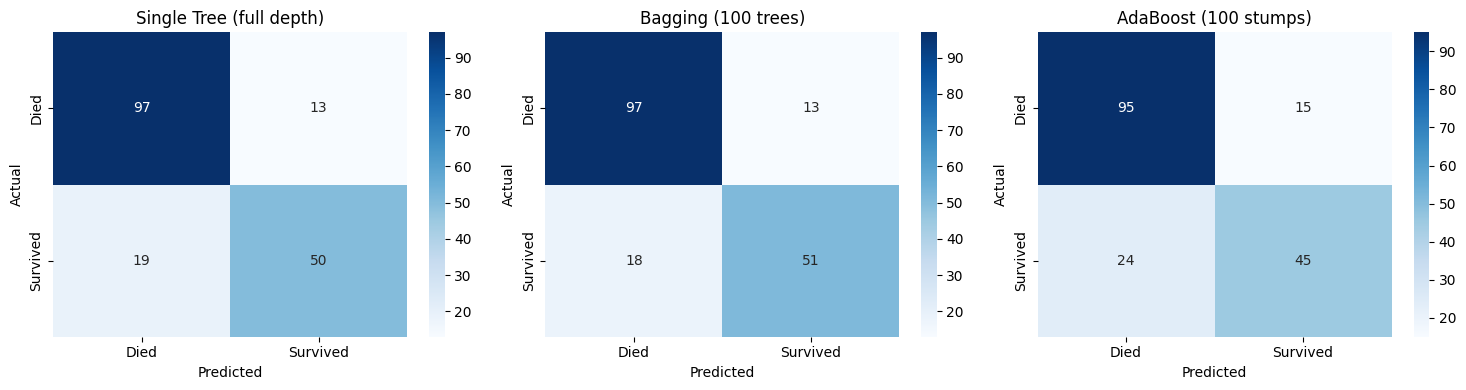

In [12]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,name in zip(axes,['Single Tree (full depth)','Bagging (100 trees)','AdaBoost (100 stumps)']):
    sns.heatmap(confusion_matrix(y_test,preds[name]),annot=True,fmt='d',cmap='Blues',ax=ax,
                xticklabels=['Died','Survived'],yticklabels=['Died','Survived'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

## A More Reliable Comparison: 5-Fold Cross-Validation
The test set has only 179 passengers, so a single split can easily favour one model by a few samples. Stratified 5-fold cross-validation evaluates every model on all 891 passengers.

In [13]:
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
models={'Single Tree (full depth)':DecisionTreeClassifier(random_state=42),
        'Single Stump (depth 1)':DecisionTreeClassifier(max_depth=1,random_state=42),
        'Bagging (100 trees)':BaggingClassifier(estimator=DecisionTreeClassifier(),n_estimators=100,random_state=42),
        'AdaBoost (100 stumps)':AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),n_estimators=100,random_state=42)}

cv_rows=[]
for name,m in models.items():
    s=cross_validate(m,X,y,cv=skf,scoring=['accuracy','precision','recall','f1'])
    cv_rows.append({'Model':name,
                    'Accuracy':s['test_accuracy'].mean(),'Accuracy std':s['test_accuracy'].std(),
                    'Precision':s['test_precision'].mean(),'Recall':s['test_recall'].mean(),
                    'F1-score':s['test_f1'].mean()})
cv_df=pd.DataFrame(cv_rows).set_index('Model')
cv_df

,Accuracy,Accuracy std,Precision,Recall,F1-score
Model,,,,,
Single Tree (full depth),0.781144,0.029304,0.706950,0.733973,0.719662
Single Stump (depth 1),0.786755,0.018807,0.743382,0.680989,0.709355
Bagging (100 trees),0.826006,0.024549,0.784644,0.754263,0.768629
AdaBoost (100 stumps),0.811474,0.016545,0.765964,0.739386,0.749434


## Effect of the Number of Estimators

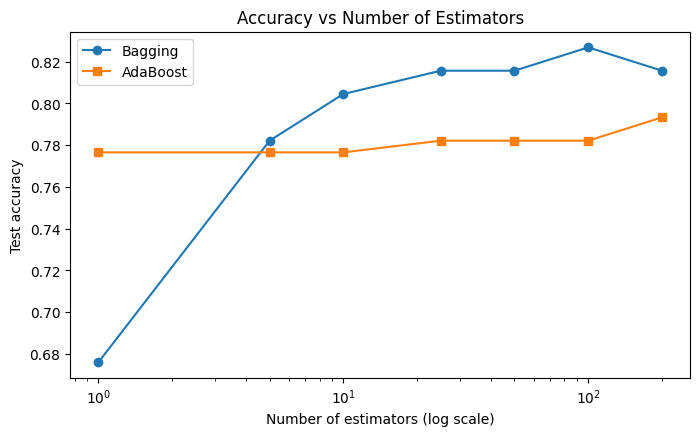

,n_estimators,Bagging,AdaBoost
0,1,0.675978,0.776536
1,5,0.782123,0.776536
2,10,0.804469,0.776536
3,25,0.815642,0.782123
4,50,0.815642,0.782123
5,100,0.826816,0.782123
6,200,0.815642,0.793296


In [14]:
n_list=[1,5,10,25,50,100,200]
bag_acc=[];ada_acc=[]
for n in n_list:
    b=BaggingClassifier(estimator=DecisionTreeClassifier(),n_estimators=n,random_state=42).fit(X_train,y_train)
    a=AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),n_estimators=n,random_state=42).fit(X_train,y_train)
    bag_acc.append(accuracy_score(y_test,b.predict(X_test)))
    ada_acc.append(accuracy_score(y_test,a.predict(X_test)))

plt.figure(figsize=(8,4.5))
plt.plot(n_list,bag_acc,marker='o',label='Bagging')
plt.plot(n_list,ada_acc,marker='s',label='AdaBoost')
plt.xscale('log')
plt.xlabel('Number of estimators (log scale)')
plt.ylabel('Test accuracy')
plt.title('Accuracy vs Number of Estimators')
plt.legend()
plt.show()
pd.DataFrame({'n_estimators':n_list,'Bagging':bag_acc,'AdaBoost':ada_acc})

## Feature Importance

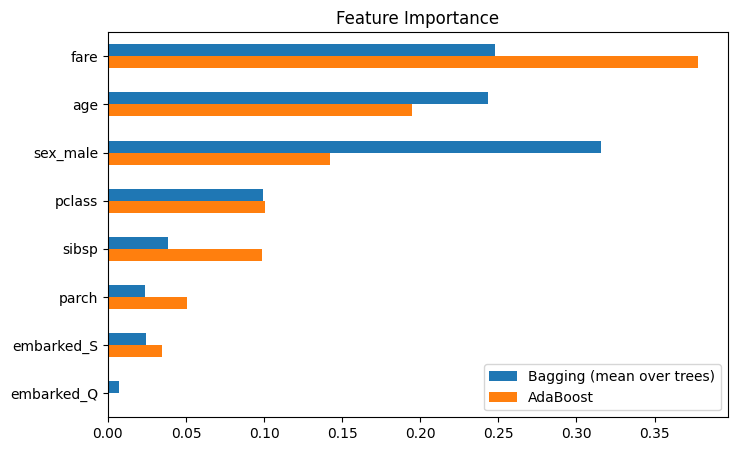

,Bagging (mean over trees),AdaBoost
fare,0.247846,0.378045
age,0.243153,0.194974
sex_male,0.315494,0.142151
pclass,0.099393,0.100930
sibsp,0.038665,0.098424
parch,0.023609,0.050658
embarked_S,0.024727,0.034818
embarked_Q,0.007112,0.000000


In [15]:
imp=pd.DataFrame({'Bagging (mean over trees)':np.mean([t.feature_importances_ for t in bag.estimators_],axis=0),
                    'AdaBoost':ada.feature_importances_},index=X.columns).sort_values('AdaBoost',ascending=False)
imp.plot(kind='barh',figsize=(8,5))
plt.title('Feature Importance')
plt.gca().invert_yaxis()
plt.show()
imp

## Discussion
**What the results show.** On the single 80/20 hold-out split, bagging (accuracy 0.827, F1 0.767) edged out a single full-depth tree (0.821, F1 0.758) and clearly beat AdaBoost (0.782, F1 0.698), which matched its one-split stump almost exactly. But the test set has only 179 passengers (one passenger is about 0.6 percentage points), so that split alone is not conclusive. Stratified 5-fold cross-validation over all 891 passengers gives a more reliable ranking: **Bagging 0.826 accuracy / 0.769 F1, AdaBoost 0.811 / 0.749, single stump 0.787 / 0.709, single full tree 0.781 / 0.720**. Note how the single tree scored 0.821 on the hold-out split but only 0.781 under CV - a direct illustration of its high variance. Both ensembles improve on their own base learner: bagging adds about 4.5 points of accuracy over the single deep tree, and AdaBoost adds about 2.5 points over its stump. Bagging finishes ahead of AdaBoost by about 1.5 points of accuracy and 2 points of F1, a gap similar in size to the fold-to-fold standard deviation (0.017-0.029), so the honest conclusion is that bagging is somewhat better here, not decisively so. Precision and recall move together: bagging has the best of both (about 0.78 and 0.75 in CV), and AdaBoost sits between the baselines and bagging.

The estimator sweep shows the different mechanisms. A single bootstrap tree (n=1) is *worse* than a tree fit on the full data (accuracy 0.676), but accuracy climbs quickly as trees are averaged (0.804 at 10 trees, about 0.82 from 25 to 100) and then levels off - adding more trees does not cause overfitting, it just stops helping. AdaBoost starts at the stump's accuracy and improves only slowly (0.777 to 0.793), because each additional stump can only make small corrections.

**How each method improves performance**
- *Bagging* trains deep, unstable trees on different bootstrap samples and votes. Each tree overfits differently, so averaging cancels much of the random error: it mainly **reduces variance** while leaving bias roughly unchanged. The free out-of-bag accuracy (0.810) is a built-in validation estimate and sits close to the cross-validated figure.
- *AdaBoost* trains stumps one after another, increasing the weight of misclassified passengers so later stumps concentrate on the hard cases, and combines them with accuracy-based vote weights. A single stump is too simple (high bias), so the sequence of corrections mainly **reduces bias**.

**Bagging - strengths:** reduces overfitting and variance; trees can be trained in parallel; robust to noisy labels and outliers; few hyperparameters to tune; gives OOB estimates for free.  
**Bagging - weaknesses:** does not reduce bias, so it cannot fix an underfitting base model; less interpretable than one tree; needs memory and time for many trees.

**AdaBoost - strengths:** turns very weak learners into a strong model; can reach high accuracy with small trees; reduces bias; works well when the weak learner is only slightly better than chance.  
**AdaBoost - weaknesses:** training is sequential, so it cannot be parallelised; sensitive to noisy labels and outliers because misclassified (possibly mislabelled) points keep gaining weight - Titanic survival is inherently noisy, which may explain why boosting did not beat bagging here; more sensitive to the number of estimators and learning rate; can overfit if run for too long.

A side note on feature importance: both ensembles rank `fare`, `age` and `sex_male` highly, but AdaBoost gives `fare` the top score (0.38) while bagging ranks `sex_male` first (0.32). Importance for tree ensembles favours continuous features that can be split many times, so these rankings should be read with caution; survival was in fact most strongly tied to sex and passenger class in the exploratory plots.

## Conclusion
Bagging (100 deep decision trees) and AdaBoost (100 stumps) were compared with single trees on the Titanic dataset after median/mode imputation and one-hot encoding. Under stratified 5-fold cross-validation, bagging achieved the best scores (accuracy 0.826, F1 0.769), AdaBoost came second (0.811, 0.749), and both beat their single-tree baselines (0.78 and 0.79 accuracy). Bagging improves a high-variance learner by averaging many independently trained models, while boosting improves a high-bias learner by sequentially focusing on misclassified samples. On this noisy dataset bagging was the safer and slightly stronger choice, although the gap to AdaBoost is small relative to the fold-to-fold variation.